# SafeFundus — Notebook 03: EfficientNet-B0 Backbone Baseline

## Purpose

This notebook trains **EfficientNet-B0** as the third backbone-screening baseline for SafeFundus.

For a fair comparison with ResNet50 v1 and DenseNet121, the training protocol is kept the same:

- Seed: **42**
- Input size: **224 × 224**
- ImageNet pretrained backbone
- Weighted BCEWithLogitsLoss
- AdamW
- Learning rate: **1e-4**
- Weight decay: **1e-4**
- Dropout: **0.30**
- Maximum epochs: **35**
- Early stopping patience: **7**
- LR scheduler patience: **3**
- Early stopping metric: **validation mAP**
- Validation-optimized per-class thresholds
- Same 14 known diseases
- Same RFMiD train/validation/test construction

Only the **backbone architecture** changes.

## Frozen RFMiD protocol

- **Known diseases:** 14
- **Training:** Normal + Known-only
- **Validation:** Normal + Known-only
- **Familiar internal test:** Normal + Known-only
- **Unknown safety test:** Unknown-only
- **Intermediate diseases:** CRVO and RPEC excluded
- **Mixed known + unknown:** excluded from the main baseline comparison

## Main outputs

The notebook saves:

- best EfficientNet-B0 checkpoint
- training history
- validation-optimized thresholds
- familiar-test predictions
- unknown-only predictions
- overall and per-class metrics
- rare-to-normal baseline safety error
- figures
- one complete ZIP:

`03_EfficientNetB0_Backbone_Baseline.zip`


In [1]:
# ============================================================
# 1. Imports
# ============================================================

from pathlib import Path
import os
import json
import random
import time
import warnings
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import EfficientNet_B0_Weights
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4


# 2. Configuration

These settings match the official ResNet50 v1 screening protocol.


In [2]:
# ============================================================
# 2. Configuration
# ============================================================

CONFIG = {
    "seed": 42,
    "image_size": 224,
    "batch_size": 32,
    "epochs": 35,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "dropout": 0.30,
    "num_workers": 2,
    "early_stopping_patience": 7,
    "lr_patience": 3,
    "threshold_grid_start": 0.05,
    "threshold_grid_end": 0.95,
    "threshold_grid_step": 0.01,
    "model_name": "efficientnet_b0",
}

DATA_ROOT = Path(
    "/kaggle/input/datasets/ozlemhakdagli/"
    "retinal-fundus-multi-disease-image-dataset-rfmid"
)

TRAIN_DIR = DATA_ROOT / "Training_set"
VAL_DIR   = DATA_ROOT / "Validation_set"
TEST_DIR  = DATA_ROOT / "Test_set"

TRAIN_CSV = TRAIN_DIR / "RFMiD_Training_Labels.csv"
VAL_CSV   = VAL_DIR   / "RFMiD_Validation_Labels.csv"
TEST_CSV  = TEST_DIR  / "RFMiD_Testing_Labels.csv"

NOTEBOOK_STEM = "03_EfficientNetB0_Backbone_Baseline"
OUTPUT_DIR = Path("/kaggle/working") / NOTEBOOK_STEM

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
TABLE_DIR = OUTPUT_DIR / "tables"
FIG_DIR = OUTPUT_DIR / "figures"
PRED_DIR = OUTPUT_DIR / "predictions"

for p in [OUTPUT_DIR, CHECKPOINT_DIR, TABLE_DIR, FIG_DIR, PRED_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print(json.dumps(CONFIG, indent=2))
print("\nOutput directory:", OUTPUT_DIR)


{
  "seed": 42,
  "image_size": 224,
  "batch_size": 32,
  "epochs": 35,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "dropout": 0.3,
  "num_workers": 2,
  "early_stopping_patience": 7,
  "lr_patience": 3,
  "threshold_grid_start": 0.05,
  "threshold_grid_end": 0.95,
  "threshold_grid_step": 0.01,
  "model_name": "efficientnet_b0"
}

Output directory: /kaggle/working/03_EfficientNetB0_Backbone_Baseline


# 3. Reproducibility


In [3]:
# ============================================================
# 3. Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CONFIG["seed"])

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)


DEVICE: cuda


# 4. Frozen Known / Unknown Disease Protocol


In [4]:
# ============================================================
# 4. Frozen disease protocol
# ============================================================

KNOWN_CLASSES = [
    "DR", "MH", "ODC", "TSLN", "DN", "MYA", "ARMD",
    "BRVO", "ODP", "ODE", "LS", "RS", "CSR", "CRS"
]

INTERMEDIATE_CLASSES = ["CRVO", "RPEC"]

print("Known classes:", len(KNOWN_CLASSES))
print(KNOWN_CLASSES)
print("\nIntermediate classes:", INTERMEDIATE_CLASSES)


Known classes: 14
['DR', 'MH', 'ODC', 'TSLN', 'DN', 'MYA', 'ARMD', 'BRVO', 'ODP', 'ODE', 'LS', 'RS', 'CSR', 'CRS']

Intermediate classes: ['CRVO', 'RPEC']


# 5. Load RFMiD Labels and Reconstruct the Frozen Image Groups


In [5]:
# ============================================================
# 5. Load labels and construct groups
# ============================================================

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

ID_COL = "ID"
RISK_COL = "Disease_Risk"

assert ID_COL in train_df.columns
assert RISK_COL in train_df.columns

DISEASE_COLS = [
    c for c in train_df.columns
    if c not in {ID_COL, RISK_COL}
]

UNKNOWN_CLASSES = [
    c for c in DISEASE_COLS
    if c not in KNOWN_CLASSES and c not in INTERMEDIATE_CLASSES
]

def assign_group(row):
    positive = {c for c in DISEASE_COLS if int(row[c]) == 1}

    if len(positive) == 0:
        return "Normal"

    if positive & set(INTERMEDIATE_CLASSES):
        return "Contains_Intermediate"

    has_known = bool(positive & set(KNOWN_CLASSES))
    has_unknown = bool(positive & set(UNKNOWN_CLASSES))

    if has_known and has_unknown:
        return "Mixed_Known_Unknown"
    if has_known:
        return "Known_Only"
    if has_unknown:
        return "Unknown_Only"

    return "Other"

for df in [train_df, val_df, test_df]:
    df["Group"] = df.apply(assign_group, axis=1)

def show_group_counts(df, name):
    print(f"\n{name}")
    display(
        df["Group"]
        .value_counts()
        .rename_axis("Group")
        .reset_index(name="Count")
    )

show_group_counts(train_df, "TRAIN")
show_group_counts(val_df, "VALIDATION")
show_group_counts(test_df, "TEST")



TRAIN


,Group,Count
0,Known_Only,1312
1,Normal,401
2,Mixed_Known_Unknown,82
3,Unknown_Only,75
4,Contains_Intermediate,50



VALIDATION


,Group,Count
0,Known_Only,426
1,Normal,134
2,Unknown_Only,34
3,Mixed_Known_Unknown,32
4,Contains_Intermediate,14



TEST


,Group,Count
0,Known_Only,437
1,Normal,134
2,Unknown_Only,32
3,Mixed_Known_Unknown,24
4,Contains_Intermediate,13


# 6. Create the Experimental Splits


In [6]:
# ============================================================
# 6. Experimental dataframes
# ============================================================

train_exp = train_df[
    train_df["Group"].isin(["Normal", "Known_Only"])
].copy()

val_exp = val_df[
    val_df["Group"].isin(["Normal", "Known_Only"])
].copy()

test_familiar = test_df[
    test_df["Group"].isin(["Normal", "Known_Only"])
].copy()

test_unknown = test_df[
    test_df["Group"] == "Unknown_Only"
].copy()

test_mixed = test_df[
    test_df["Group"] == "Mixed_Known_Unknown"
].copy()

print("Training images       :", len(train_exp))
print("Validation images     :", len(val_exp))
print("Familiar test images  :", len(test_familiar))
print("Unknown-only test     :", len(test_unknown))
print("Mixed exploratory test:", len(test_mixed))

assert len(train_exp) == 1713
assert len(val_exp) == 560
assert len(test_unknown) == 32
assert len(test_mixed) == 24

print("\n✓ Frozen protocol verified.")


Training images       : 1713
Validation images     : 560
Familiar test images  : 571
Unknown-only test     : 32
Mixed exploratory test: 24

✓ Frozen protocol verified.


# 7. Verify Image Paths


In [7]:
# ============================================================
# 7. Add image paths
# ============================================================

def normalize_id(x):
    return str(int(float(x)))

def add_image_paths(df, folder):
    out = df.copy()

    out["image_path"] = out[ID_COL].apply(
        lambda x: str(folder / f"{normalize_id(x)}.png")
    )

    missing = [
        p for p in out["image_path"]
        if not Path(p).exists()
    ]

    if missing:
        raise FileNotFoundError(
            f"{len(missing)} image files are missing. "
            f"Example: {missing[:3]}"
        )

    return out

train_exp = add_image_paths(train_exp, TRAIN_DIR)
val_exp = add_image_paths(val_exp, VAL_DIR)
test_familiar = add_image_paths(test_familiar, TEST_DIR)
test_unknown = add_image_paths(test_unknown, TEST_DIR)
test_mixed = add_image_paths(test_mixed, TEST_DIR)

print("All image paths verified.")


All image paths verified.


# 8. Preprocessing and Augmentation

This matches the ResNet50 v1 augmentation protocol.


In [8]:
# ============================================================
# 8. Transforms
# ============================================================

weights = EfficientNet_B0_Weights.IMAGENET1K_V1
imagenet_mean = weights.transforms().mean
imagenet_std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize(
        (CONFIG["image_size"], CONFIG["image_size"])
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.08,
        hue=0.02,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std,
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (CONFIG["image_size"], CONFIG["image_size"])
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=imagenet_mean,
        std=imagenet_std,
    ),
])

print("ImageNet mean:", imagenet_mean)
print("ImageNet std :", imagenet_std)


ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std : [0.229, 0.224, 0.225]


# 9. PyTorch Dataset


In [9]:
# ============================================================
# 9. Dataset
# ============================================================

class RFMiDDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        target = torch.tensor(
            row[KNOWN_CLASSES]
            .astype(np.float32)
            .values,
            dtype=torch.float32,
        )

        return {
            "image": image,
            "target": target,
            "id": normalize_id(row[ID_COL]),
            "group": row["Group"],
        }

train_dataset = RFMiDDataset(train_exp, train_transform)
val_dataset = RFMiDDataset(val_exp, eval_transform)
test_familiar_dataset = RFMiDDataset(test_familiar, eval_transform)
test_unknown_dataset = RFMiDDataset(test_unknown, eval_transform)

print("Train dataset     :", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Familiar test     :", len(test_familiar_dataset))
print("Unknown test      :", len(test_unknown_dataset))


Train dataset     : 1713
Validation dataset: 560
Familiar test     : 571
Unknown test      : 32


# 10. DataLoaders


In [10]:
# ============================================================
# 10. DataLoaders
# ============================================================

def seed_worker(worker_id):
    worker_seed = CONFIG["seed"] + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

generator = torch.Generator()
generator.manual_seed(CONFIG["seed"])

train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
    worker_init_fn=seed_worker,
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
)

test_familiar_loader = DataLoader(
    test_familiar_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
)

test_unknown_loader = DataLoader(
    test_unknown_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    persistent_workers=CONFIG["num_workers"] > 0,
)

batch = next(iter(train_loader))

print("Image batch shape :", batch["image"].shape)
print("Target batch shape:", batch["target"].shape)


Image batch shape : torch.Size([32, 3, 224, 224])
Target batch shape: torch.Size([32, 14])


# 11. Weighted BCE for Class Imbalance


In [11]:
# ============================================================
# 11. Positive class weights
# ============================================================

positive_counts = train_exp[
    KNOWN_CLASSES
].sum(axis=0).astype(float)

negative_counts = (
    len(train_exp) - positive_counts
)

pos_weight = (
    negative_counts /
    np.maximum(positive_counts, 1.0)
)

pos_weight = np.minimum(
    pos_weight,
    20.0,
)

class_balance_df = pd.DataFrame({
    "Disease": KNOWN_CLASSES,
    "Positive_Train": positive_counts.values.astype(int),
    "Negative_Train": negative_counts.values.astype(int),
    "Pos_Weight": pos_weight.values,
})

display(class_balance_df)

class_balance_df.to_csv(
    TABLE_DIR / "efficientnetb0_class_balance.csv",
    index=False,
)

POS_WEIGHT_TENSOR = torch.tensor(
    pos_weight.values,
    dtype=torch.float32,
    device=DEVICE,
)


,Disease,Positive_Train,Negative_Train,Pos_Weight
0,DR,358,1355,3.784916
1,MH,306,1407,4.598039
2,ODC,261,1452,5.563218
3,TSLN,174,1539,8.844828
4,DN,126,1587,12.595238
5,MYA,99,1614,16.303030
6,ARMD,92,1621,17.619565
7,BRVO,71,1642,20.000000
8,ODP,52,1661,20.000000
9,ODE,53,1660,20.000000


# 12. Build EfficientNet-B0

Torchvision EfficientNet-B0 already uses a classifier block. We replace it with:

Dropout(0.30) → Linear(features → 14)


In [12]:
# ============================================================
# 12. Model
# ============================================================

def build_efficientnet_b0(
    num_classes,
    dropout=0.3,
):
    try:
        model = models.efficientnet_b0(
            weights=EfficientNet_B0_Weights.IMAGENET1K_V1
        )

        print(
            "Loaded ImageNet pretrained "
            "EfficientNet-B0 weights."
        )

    except Exception as e:
        print(
            "WARNING: Could not load "
            "pretrained weights."
        )
        print("Reason:", e)

        print(
            "\nFor the real experiment, enable Kaggle Internet "
            "or provide pretrained weights. Training from scratch "
            "is NOT recommended."
        )

        model = models.efficientnet_b0(
            weights=None
        )

    in_features = (
        model.classifier[1].in_features
    )

    model.classifier = nn.Sequential(
        nn.Dropout(
            p=dropout,
            inplace=True,
        ),
        nn.Linear(
            in_features,
            num_classes,
        ),
    )

    return model

model = build_efficientnet_b0(
    num_classes=len(KNOWN_CLASSES),
    dropout=CONFIG["dropout"],
).to(DEVICE)

print(model.classifier)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 184MB/s]

Loaded ImageNet pretrained EfficientNet-B0 weights.
Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1280, out_features=14, bias=True)
)


# 13. Loss, Optimizer, Scheduler


In [13]:
# ============================================================
# 13. Training components
# ============================================================

criterion = nn.BCEWithLogitsLoss(
    pos_weight=POS_WEIGHT_TENSOR
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"],
)

scheduler = (
    torch.optim.lr_scheduler
    .ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=CONFIG["lr_patience"],
    )
)

scaler = torch.cuda.amp.GradScaler(
    enabled=(DEVICE.type == "cuda")
)

print("Loss      : BCEWithLogitsLoss + pos_weight")
print("Optimizer : AdamW")
print("Scheduler : ReduceLROnPlateau on validation mAP")
print("AMP       :", DEVICE.type == "cuda")


Loss      : BCEWithLogitsLoss + pos_weight
Optimizer : AdamW
Scheduler : ReduceLROnPlateau on validation mAP
AMP       : True


# 14. Metric Functions


In [14]:
# ============================================================
# 14. Metrics
# ============================================================

def safe_macro_auroc(y_true, y_prob):
    scores = []

    for c in range(y_true.shape[1]):
        if len(np.unique(y_true[:, c])) < 2:
            continue

        scores.append(
            roc_auc_score(
                y_true[:, c],
                y_prob[:, c],
            )
        )

    return float(np.mean(scores)) if scores else np.nan

def safe_map(y_true, y_prob):
    scores = []

    for c in range(y_true.shape[1]):
        if y_true[:, c].sum() == 0:
            continue

        scores.append(
            average_precision_score(
                y_true[:, c],
                y_prob[:, c],
            )
        )

    return float(np.mean(scores)) if scores else np.nan

def compute_epoch_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)

    return {
        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "micro_f1": f1_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0,
        ),
        "mAP": safe_map(
            y_true,
            y_prob,
        ),
        "macro_auroc": safe_macro_auroc(
            y_true,
            y_prob,
        ),
    }


# 15. Training and Validation Functions


In [15]:
# ============================================================
# 15. Train / validation functions
# ============================================================

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
):
    model.train()

    running_loss = 0.0
    all_targets = []
    all_probs = []

    pbar = tqdm(
        loader,
        desc="Train",
        leave=False,
    )

    for batch in pbar:
        images = batch["image"].to(
            DEVICE,
            non_blocking=True,
        )

        targets = batch["target"].to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.cuda.amp.autocast(
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(images)
            loss = criterion(
                logits,
                targets,
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        probs = torch.sigmoid(logits)

        running_loss += (
            loss.item() *
            images.size(0)
        )

        all_targets.append(
            targets.detach()
            .cpu()
            .numpy()
        )

        all_probs.append(
            probs.detach()
            .cpu()
            .numpy()
        )

        pbar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    y_true = np.concatenate(all_targets)
    y_prob = np.concatenate(all_probs)

    metrics = compute_epoch_metrics(
        y_true,
        y_prob,
    )

    metrics["loss"] = (
        running_loss /
        len(loader.dataset)
    )

    return metrics


@torch.no_grad()
def evaluate_loader(
    model,
    loader,
    criterion=None,
):
    model.eval()

    running_loss = 0.0
    all_targets = []
    all_probs = []
    all_logits = []
    all_ids = []
    all_groups = []

    for batch in tqdm(
        loader,
        desc="Evaluate",
        leave=False,
    ):
        images = batch["image"].to(
            DEVICE,
            non_blocking=True,
        )

        targets = batch["target"].to(
            DEVICE,
            non_blocking=True,
        )

        with torch.cuda.amp.autocast(
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(images)

            if criterion is not None:
                loss = criterion(
                    logits,
                    targets,
                )

                running_loss += (
                    loss.item() *
                    images.size(0)
                )

        probs = torch.sigmoid(logits)

        all_targets.append(
            targets.cpu().numpy()
        )

        all_probs.append(
            probs.cpu().numpy()
        )

        all_logits.append(
            logits.cpu().numpy()
        )

        all_ids.extend(
            batch["id"]
        )

        all_groups.extend(
            batch["group"]
        )

    y_true = np.concatenate(all_targets)
    y_prob = np.concatenate(all_probs)
    logits = np.concatenate(all_logits)

    metrics = compute_epoch_metrics(
        y_true,
        y_prob,
    )

    if criterion is not None:
        metrics["loss"] = (
            running_loss /
            len(loader.dataset)
        )

    return {
        "metrics": metrics,
        "targets": y_true,
        "probs": y_prob,
        "logits": logits,
        "ids": all_ids,
        "groups": all_groups,
    }


# 16. Train EfficientNet-B0

The best checkpoint is selected by **validation mAP**.


In [16]:
# ============================================================
# 16. Training
# ============================================================

history = []

best_val_map = -np.inf
epochs_without_improvement = 0

best_checkpoint_path = (
    CHECKPOINT_DIR /
    "best_efficientnetb0_rfmid.pth"
)

start_time = time.time()

for epoch in range(
    1,
    CONFIG["epochs"] + 1,
):
    print(f"\n{'='*70}")
    print(
        f"Epoch {epoch}/"
        f"{CONFIG['epochs']}"
    )
    print(f"{'='*70}")

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
    )

    val_result = evaluate_loader(
        model,
        val_loader,
        criterion,
    )

    val_metrics = val_result["metrics"]

    scheduler.step(
        val_metrics["mAP"]
    )

    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "lr": current_lr,

        "train_loss": train_metrics["loss"],
        "train_macro_f1": train_metrics["macro_f1"],
        "train_micro_f1": train_metrics["micro_f1"],
        "train_mAP": train_metrics["mAP"],
        "train_macro_auroc": train_metrics["macro_auroc"],

        "val_loss": val_metrics["loss"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_micro_f1": val_metrics["micro_f1"],
        "val_mAP": val_metrics["mAP"],
        "val_macro_auroc": val_metrics["macro_auroc"],
    }

    history.append(row)

    print(
        f"Train Loss={train_metrics['loss']:.4f} | "
        f"mAP={train_metrics['mAP']:.4f} | "
        f"Macro-F1={train_metrics['macro_f1']:.4f}"
    )

    print(
        f"Val   Loss={val_metrics['loss']:.4f} | "
        f"mAP={val_metrics['mAP']:.4f} | "
        f"Macro-F1={val_metrics['macro_f1']:.4f} | "
        f"AUROC={val_metrics['macro_auroc']:.4f}"
    )

    print(f"LR={current_lr:.2e}")

    if val_metrics["mAP"] > best_val_map:
        best_val_map = val_metrics["mAP"]
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "config": CONFIG,
            "known_classes": KNOWN_CLASSES,
            "best_val_map": best_val_map,
            "epoch": epoch,
        }, best_checkpoint_path)

        print(
            "✓ New best checkpoint saved: "
            f"val mAP={best_val_map:.4f}"
        )
    else:
        epochs_without_improvement += 1

        print(
            "No validation mAP improvement for "
            f"{epochs_without_improvement} epoch(s)."
        )

    if (
        epochs_without_improvement >=
        CONFIG["early_stopping_patience"]
    ):
        print("\nEarly stopping triggered.")
        break

elapsed_minutes = (
    time.time() - start_time
) / 60

history_df = pd.DataFrame(history)

history_df.to_csv(
    TABLE_DIR /
    "efficientnetb0_training_history.csv",
    index=False,
)

print(
    f"\nTraining finished in "
    f"{elapsed_minutes:.1f} minutes."
)

print(
    "Best validation mAP:",
    best_val_map,
)

print(
    "Best checkpoint:",
    best_checkpoint_path,
)

display(history_df.tail())



Epoch 1/35


Train:   0%|          | 0/54 [00:07<?, ?it/s]

Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss=1.0633 | mAP=0.1702 | Macro-F1=0.1876
Val   Loss=0.9534 | mAP=0.3192 | Macro-F1=0.2565 | AUROC=0.7860
LR=1.00e-04
✓ New best checkpoint saved: val mAP=0.3192

Epoch 2/35


Train:   0%|          | 0/54 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

... (97 outputs left out)

Train:   0%|          | 0/54 [00:00<?, ?it/s]

Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

Train Loss=0.0707 | mAP=0.9918 | Macro-F1=0.9167
Val   Loss=0.8393 | mAP=0.6713 | Macro-F1=0.6259 | AUROC=0.9170
LR=2.50e-05
No validation mAP improvement for 6 epoch(s).

Training finished in 100.3 minutes.
Best validation mAP: 0.6733732269282898
Best checkpoint: /kaggle/working/03_EfficientNetB0_Backbone_Baseline/checkpoints/best_efficientnetb0_rfmid.pth


,epoch,lr,train_loss,train_macro_f1,train_micro_f1,train_mAP,train_macro_auroc,val_loss,val_macro_f1,val_micro_f1,val_mAP,val_macro_auroc
30,31,0.000050,0.074772,0.899876,0.908271,0.990309,0.998872,0.807766,0.613715,0.659859,0.666234,0.919893
31,32,0.000050,0.080347,0.899762,0.905163,0.983902,0.998231,0.838483,0.623546,0.664025,0.667760,0.921777
32,33,0.000025,0.072004,0.913368,0.913171,0.991928,0.998824,0.827810,0.621904,0.664013,0.670022,0.920446
33,34,0.000025,0.072206,0.917890,0.919238,0.990929,0.998913,0.845048,0.635191,0.666134,0.669630,0.921640
34,35,0.000025,0.070743,0.916734,0.913936,0.991829,0.998857,0.839319,0.625939,0.657210,0.671304,0.916989


# 17. Training Curves and Generalization Diagnostic


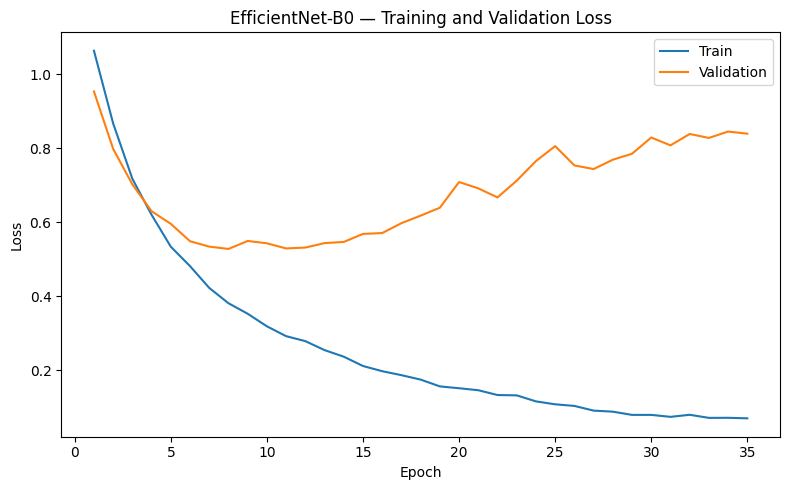

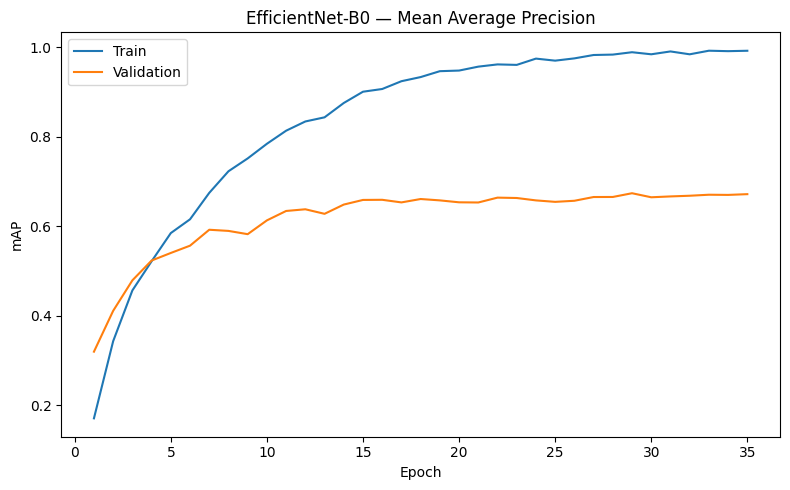

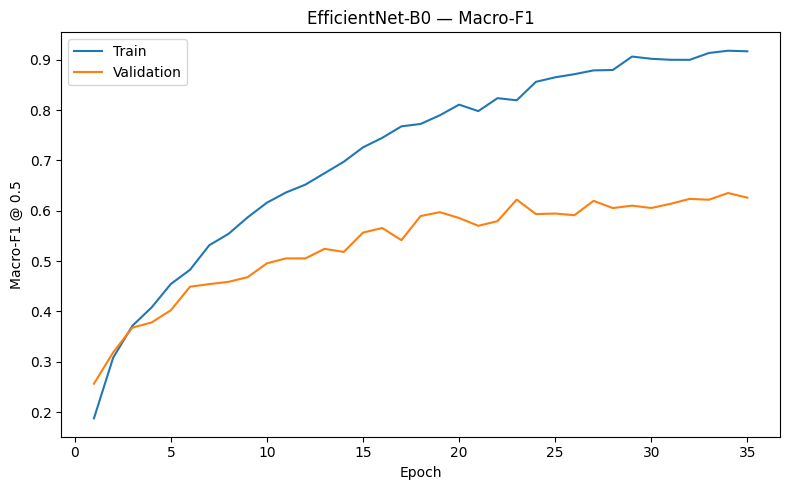

{
  "best_history_epoch": 29,
  "train_mAP_at_best_val": 0.9885571498812705,
  "val_mAP_at_best_val": 0.6733732269282898,
  "mAP_generalization_gap": 0.3151839229529807
}


In [17]:
# ============================================================
# 17. Training curves
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train",
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "EfficientNet-B0 — "
    "Training and Validation Loss"
)
plt.legend()
plt.tight_layout()
plt.savefig(
    FIG_DIR /
    "efficientnetb0_loss_curve.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_mAP"],
    label="Train",
)
plt.plot(
    history_df["epoch"],
    history_df["val_mAP"],
    label="Validation",
)
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title(
    "EfficientNet-B0 — "
    "Mean Average Precision"
)
plt.legend()
plt.tight_layout()
plt.savefig(
    FIG_DIR /
    "efficientnetb0_map_curve.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train",
)
plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation",
)
plt.xlabel("Epoch")
plt.ylabel("Macro-F1 @ 0.5")
plt.title(
    "EfficientNet-B0 — Macro-F1"
)
plt.legend()
plt.tight_layout()
plt.savefig(
    FIG_DIR /
    "efficientnetb0_macro_f1_curve.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

best_history_row = (
    history_df
    .loc[
        history_df["val_mAP"].idxmax()
    ]
)

generalization_diagnostics = {
    "best_history_epoch":
        int(best_history_row["epoch"]),
    "train_mAP_at_best_val":
        float(
            best_history_row["train_mAP"]
        ),
    "val_mAP_at_best_val":
        float(
            best_history_row["val_mAP"]
        ),
    "mAP_generalization_gap":
        float(
            best_history_row["train_mAP"]
            -
            best_history_row["val_mAP"]
        ),
}

print(
    json.dumps(
        generalization_diagnostics,
        indent=2,
    )
)

with open(
    TABLE_DIR /
    "efficientnetb0_generalization_diagnostics.json",
    "w",
) as f:
    json.dump(
        generalization_diagnostics,
        f,
        indent=2,
    )


# 18. Load the Best Checkpoint


In [18]:
# ============================================================
# 18. Load best model
# ============================================================

checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print(
    "Loaded checkpoint from epoch:",
    checkpoint["epoch"],
)

print(
    "Best validation mAP:",
    checkpoint["best_val_map"],
)


Loaded checkpoint from epoch: 29
Best validation mAP: 0.6733732269282898


# 19. Optimize Per-Class Thresholds on Validation Data Only


In [19]:
# ============================================================
# 19. Threshold optimization
# ============================================================

val_result = evaluate_loader(
    model,
    val_loader,
)

val_true = val_result["targets"]
val_prob = val_result["probs"]

threshold_grid = np.arange(
    CONFIG["threshold_grid_start"],
    CONFIG["threshold_grid_end"] + 1e-9,
    CONFIG["threshold_grid_step"],
)

def optimize_thresholds(
    y_true,
    y_prob,
):
    thresholds = []

    for c, disease in enumerate(
        KNOWN_CLASSES
    ):
        best_threshold = 0.5
        best_f1 = -1.0

        if y_true[:, c].sum() == 0:
            thresholds.append(
                best_threshold
            )
            continue

        for threshold in threshold_grid:
            pred = (
                y_prob[:, c] >= threshold
            ).astype(int)

            score = f1_score(
                y_true[:, c],
                pred,
                zero_division=0,
            )

            if score > best_f1:
                best_f1 = score
                best_threshold = float(
                    threshold
                )

        thresholds.append(
            best_threshold
        )

    return np.array(
        thresholds,
        dtype=np.float32,
    )

CLASS_THRESHOLDS = optimize_thresholds(
    val_true,
    val_prob,
)

threshold_df = pd.DataFrame({
    "Disease": KNOWN_CLASSES,
    "Threshold": CLASS_THRESHOLDS,
})

display(threshold_df)

threshold_df.to_csv(
    TABLE_DIR /
    "efficientnetb0_validation_thresholds.csv",
    index=False,
)


Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

,Disease,Threshold
0,DR,0.93
1,MH,0.39
2,ODC,0.73
3,TSLN,0.60
4,DN,0.75
5,MYA,0.52
6,ARMD,0.84
7,BRVO,0.80
8,ODP,0.09
9,ODE,0.75


# 20. Familiar-Test Evaluation


In [20]:
# ============================================================
# 20. Familiar-test evaluation
# ============================================================

familiar_result = evaluate_loader(
    model,
    test_familiar_loader,
)

y_true = familiar_result["targets"]
y_prob = familiar_result["probs"]

y_pred = (
    y_prob >=
    CLASS_THRESHOLDS[None, :]
).astype(int)

overall_metrics = {
    "model": "EfficientNet-B0",
    "seed": CONFIG["seed"],
    "familiar_test_images":
        int(len(y_true)),
    "macro_f1": float(
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    ),
    "micro_f1": float(
        f1_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0,
        )
    ),
    "mAP": safe_map(
        y_true,
        y_prob,
    ),
    "macro_auroc":
        safe_macro_auroc(
            y_true,
            y_prob,
        ),
}

print(
    json.dumps(
        overall_metrics,
        indent=2,
    )
)

with open(
    TABLE_DIR /
    "efficientnetb0_overall_metrics.json",
    "w",
) as f:
    json.dump(
        overall_metrics,
        f,
        indent=2,
    )


Evaluate:   0%|          | 0/18 [00:00<?, ?it/s]

{
  "model": "EfficientNet-B0",
  "seed": 42,
  "familiar_test_images": 571,
  "macro_f1": 0.6504160977381579,
  "micro_f1": 0.6522462562396006,
  "mAP": 0.7037115272197548,
  "macro_auroc": 0.9348044028987615
}


# 21. Per-Disease Metrics


In [21]:
# ============================================================
# 21. Per-class metrics
# ============================================================

rows = []

for c, disease in enumerate(
    KNOWN_CLASSES
):
    yt = y_true[:, c]
    yp = y_pred[:, c]
    prob = y_prob[:, c]

    tn, fp, fn, tp = (
        confusion_matrix(
            yt,
            yp,
            labels=[0, 1],
        ).ravel()
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    auroc = (
        roc_auc_score(
            yt,
            prob,
        )
        if len(np.unique(yt)) == 2
        else np.nan
    )

    ap = (
        average_precision_score(
            yt,
            prob,
        )
        if yt.sum() > 0
        else np.nan
    )

    rows.append({
        "Disease": disease,
        "Positive_Test":
            int(yt.sum()),
        "Threshold":
            float(
                CLASS_THRESHOLDS[c]
            ),
        "Precision":
            precision_score(
                yt,
                yp,
                zero_division=0,
            ),
        "Sensitivity_Recall":
            recall_score(
                yt,
                yp,
                zero_division=0,
            ),
        "Specificity":
            specificity,
        "F1":
            f1_score(
                yt,
                yp,
                zero_division=0,
            ),
        "AUROC":
            auroc,
        "Average_Precision":
            ap,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    })

per_class_metrics = pd.DataFrame(rows)

display(per_class_metrics)

per_class_metrics.to_csv(
    TABLE_DIR /
    "efficientnetb0_per_class_metrics.csv",
    index=False,
)


,Disease,Positive_Test,Threshold,Precision,Sensitivity_Recall,Specificity,F1,AUROC,Average_Precision,TP,FP,TN,FN
0,DR,122,0.93,0.940000,0.770492,0.986637,0.846847,0.974607,0.917160,94,6,443,28
1,MH,100,0.39,0.671642,0.900000,0.906582,0.769231,0.976635,0.913668,90,44,427,10
2,ODC,84,0.73,0.583333,0.500000,0.938398,0.538462,0.844065,0.609929,42,30,457,42
3,TSLN,49,0.60,0.536232,0.755102,0.938697,0.627119,0.960220,0.723395,37,32,490,12
4,DN,45,0.75,0.314286,0.244444,0.954373,0.275000,0.799092,0.246966,11,24,502,34
5,MYA,29,0.52,0.722222,0.896552,0.981550,0.800000,0.993542,0.907211,26,10,532,3
6,ARMD,27,0.84,0.791667,0.703704,0.990809,0.745098,0.985839,0.809970,19,5,539,8
7,BRVO,23,0.80,0.904762,0.826087,0.996350,0.863636,0.950651,0.847794,19,2,546,4
8,ODP,22,0.09,0.139785,0.590909,0.854281,0.226087,0.809488,0.328838,13,80,469,9
9,ODE,16,0.75,1.000000,0.812500,1.000000,0.896552,0.964640,0.836108,13,0,555,3


# 22. Save Familiar-Test Predictions


In [22]:
# ============================================================
# 22. Save familiar-test predictions
# ============================================================

pred_df = pd.DataFrame({
    "ID": familiar_result["ids"],
    "Group": familiar_result["groups"],
})

for c, disease in enumerate(
    KNOWN_CLASSES
):
    pred_df[
        f"true_{disease}"
    ] = y_true[:, c].astype(int)

    pred_df[
        f"logit_{disease}"
    ] = (
        familiar_result["logits"]
        [:, c]
    )

    pred_df[
        f"prob_{disease}"
    ] = y_prob[:, c]

    pred_df[
        f"pred_{disease}"
    ] = y_pred[:, c].astype(int)

pred_df.to_csv(
    PRED_DIR /
    "efficientnetb0_familiar_test_predictions.csv",
    index=False,
)

display(pred_df.head())


,ID,Group,true_DR,logit_DR,prob_DR,pred_DR,true_MH,logit_MH,prob_MH,pred_MH,...,prob_RS,pred_RS,true_CSR,logit_CSR,prob_CSR,pred_CSR,true_CRS,logit_CRS,prob_CRS,pred_CRS
0,1,Known_Only,1,5.535156,0.996094,1,0,-4.148438,0.015541,0,...,0.000066,0,0,-9.648438,0.000065,0,0,-7.992188,0.000338,0
1,2,Known_Only,1,-4.238281,0.014229,0,0,-7.003906,0.000907,0,...,0.000675,0,0,-7.574219,0.000513,0,0,-4.648438,0.009483,0
2,3,Known_Only,1,-0.990234,0.270752,0,0,-1.878906,0.132568,0,...,0.003483,0,0,-7.007812,0.000904,0,0,-4.804688,0.008125,0
3,9,Known_Only,1,4.664062,0.990723,1,0,-3.492188,0.029541,0,...,0.006413,0,0,-6.957031,0.000951,0,0,-4.308594,0.013275,0
4,10,Known_Only,1,8.734375,1.000000,1,0,-6.281250,0.001867,0,...,0.000521,0,0,-7.257812,0.000704,0,0,-5.828125,0.002935,0


# 23. Closed-Set Safety Test on Unknown Rare Diseases


In [23]:
# ============================================================
# 23. Unknown-only safety evaluation
# ============================================================

unknown_result = evaluate_loader(
    model,
    test_unknown_loader,
)

unknown_prob = unknown_result["probs"]

unknown_pred = (
    unknown_prob >=
    CLASS_THRESHOLDS[None, :]
).astype(int)

unknown_predicted_normal = (
    unknown_pred.sum(axis=1) == 0
)

rare_to_normal_count = int(
    unknown_predicted_normal.sum()
)

rare_to_normal_rate = float(
    unknown_predicted_normal.mean()
)

unknown_forced_into_known_rate = float(
    (~unknown_predicted_normal).mean()
)

safety_metrics = {
    "model": "EfficientNet-B0",
    "unknown_only_test_images":
        int(len(unknown_pred)),
    "rare_to_normal_count":
        rare_to_normal_count,
    "rare_to_normal_error_rate":
        rare_to_normal_rate,
    "unknown_forced_into_known_rate":
        unknown_forced_into_known_rate,
}

print(
    json.dumps(
        safety_metrics,
        indent=2,
    )
)

with open(
    TABLE_DIR /
    "efficientnetb0_unknown_safety_metrics.json",
    "w",
) as f:
    json.dump(
        safety_metrics,
        f,
        indent=2,
    )


Evaluate:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "model": "EfficientNet-B0",
  "unknown_only_test_images": 32,
  "rare_to_normal_count": 10,
  "rare_to_normal_error_rate": 0.3125,
  "unknown_forced_into_known_rate": 0.6875
}


# 24. Save Unknown-Only Predictions


In [24]:
# ============================================================
# 24. Save unknown-only predictions
# ============================================================

unknown_pred_df = pd.DataFrame({
    "ID": unknown_result["ids"],
    "Group": unknown_result["groups"],
    "Predicted_Normal":
        unknown_predicted_normal.astype(int),
    "Num_Known_Diseases_Predicted":
        unknown_pred.sum(axis=1).astype(int),
    "Max_Known_Probability":
        unknown_prob.max(axis=1),
})

for c, disease in enumerate(
    KNOWN_CLASSES
):
    unknown_pred_df[
        f"logit_{disease}"
    ] = (
        unknown_result["logits"]
        [:, c]
    )

    unknown_pred_df[
        f"prob_{disease}"
    ] = unknown_prob[:, c]

    unknown_pred_df[
        f"pred_{disease}"
    ] = (
        unknown_pred[:, c]
        .astype(int)
    )

unknown_pred_df.to_csv(
    PRED_DIR /
    "efficientnetb0_unknown_test_predictions.csv",
    index=False,
)

display(
    unknown_pred_df
    .sort_values(
        "Max_Known_Probability",
        ascending=False,
    )
    .head(10)
)


,ID,Group,Predicted_Normal,Num_Known_Diseases_Predicted,Max_Known_Probability,logit_DR,prob_DR,pred_DR,logit_MH,prob_MH,...,pred_LS,logit_RS,prob_RS,pred_RS,logit_CSR,prob_CSR,pred_CSR,logit_CRS,prob_CRS,pred_CRS
0,4,Unknown_Only,0,1,0.999512,-4.949219,0.007038,0,-5.316406,0.004887,...,0,-5.136719,0.005844,0,-5.738281,0.003210,0,-4.085938,0.016525,0
14,150,Unknown_Only,0,1,0.999512,-3.628906,0.025864,0,7.273438,0.999512,...,0,-6.988281,0.000922,0,-7.082031,0.000839,0,-7.300781,0.000675,0
9,26,Unknown_Only,0,2,0.999023,6.941406,0.999023,1,-2.669922,0.064758,...,1,-6.277344,0.001875,0,-6.269531,0.001889,0,-1.661133,0.159668,0
25,486,Unknown_Only,0,1,0.997559,-0.709473,0.329834,0,-5.109375,0.006004,...,0,6.039062,0.997559,1,-4.996094,0.006718,0,-2.705078,0.062683,0
6,13,Unknown_Only,0,1,0.993652,-0.443115,0.391113,0,-1.696289,0.154907,...,0,-3.656250,0.025177,0,-4.500000,0.010986,0,-5.285156,0.005039,0
2,6,Unknown_Only,0,1,0.991699,-1.775391,0.144897,0,-3.000000,0.047424,...,0,-2.451172,0.079346,0,-7.105469,0.000820,0,-0.424072,0.395508,0
3,7,Unknown_Only,0,1,0.990234,-5.664062,0.003456,0,-8.734375,0.000161,...,0,-2.361328,0.086182,0,-5.917969,0.002684,0,-2.048828,0.114197,0
12,58,Unknown_Only,0,1,0.986816,-2.888672,0.052704,0,-5.136719,0.005844,...,0,-6.109375,0.002216,0,-8.937500,0.000131,0,-1.157227,0.239136,0
21,440,Unknown_Only,0,1,0.979980,-4.132812,0.015778,0,-6.472656,0.001543,...,0,-4.031250,0.017441,0,-3.748047,0.023026,0,-1.723633,0.151367,0
7,16,Unknown_Only,0,2,0.979492,-3.056641,0.044922,0,-5.878906,0.002790,...,0,-5.140625,0.005821,0,0.472412,0.615723,1,-4.734375,0.008713,0


# 25. Final EfficientNet-B0 Summary


In [25]:
# ============================================================
# 25. Final summary
# ============================================================

summary = {
    **overall_metrics,
    **safety_metrics,
    **generalization_diagnostics,
    "best_epoch":
        int(checkpoint["epoch"]),
    "best_validation_mAP":
        float(
            checkpoint["best_val_map"]
        ),
}

print("=" * 70)
print(
    "EFFICIENTNET-B0 BACKBONE "
    "BASELINE SUMMARY"
)
print("=" * 70)

for key, value in summary.items():
    if isinstance(value, float):
        print(
            f"{key:38s}: "
            f"{value:.6f}"
        )
    else:
        print(
            f"{key:38s}: "
            f"{value}"
        )

with open(
    TABLE_DIR /
    "efficientnetb0_summary.json",
    "w",
) as f:
    json.dump(
        summary,
        f,
        indent=2,
    )


EFFICIENTNET-B0 BACKBONE BASELINE SUMMARY
model                                 : EfficientNet-B0
seed                                  : 42
familiar_test_images                  : 571
macro_f1                              : 0.650416
micro_f1                              : 0.652246
mAP                                   : 0.703712
macro_auroc                           : 0.934804
unknown_only_test_images              : 32
rare_to_normal_count                  : 10
rare_to_normal_error_rate             : 0.312500
unknown_forced_into_known_rate        : 0.687500
best_history_epoch                    : 29
train_mAP_at_best_val                 : 0.988557
val_mAP_at_best_val                   : 0.673373
mAP_generalization_gap                : 0.315184
best_epoch                            : 29
best_validation_mAP                   : 0.673373


# 26. Save Configuration and Frozen Protocol


In [26]:
# ============================================================
# 26. Save configuration and protocol
# ============================================================

with open(
    OUTPUT_DIR / "config.json",
    "w",
) as f:
    json.dump(
        CONFIG,
        f,
        indent=2,
    )

protocol = {
    "known_classes":
        KNOWN_CLASSES,
    "unknown_classes":
        UNKNOWN_CLASSES,
    "intermediate_classes":
        INTERMEDIATE_CLASSES,
    "train_images":
        len(train_exp),
    "validation_images":
        len(val_exp),
    "familiar_test_images":
        len(test_familiar),
    "unknown_only_test_images":
        len(test_unknown),
    "mixed_test_images":
        len(test_mixed),
}

with open(
    OUTPUT_DIR /
    "frozen_protocol.json",
    "w",
) as f:
    json.dump(
        protocol,
        f,
        indent=2,
    )


# 27. Create One Complete Output ZIP

The notebook automatically creates:

`/kaggle/working/03_EfficientNetB0_Backbone_Baseline.zip`


In [27]:
# ============================================================
# 27. Create complete ZIP
# ============================================================

ZIP_PATH = (
    Path("/kaggle/working") /
    f"{NOTEBOOK_STEM}.zip"
)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

archive_base = str(
    ZIP_PATH.with_suffix("")
)

shutil.make_archive(
    base_name=archive_base,
    format="zip",
    root_dir=OUTPUT_DIR,
)

print("=" * 70)
print("COMPLETE OUTPUT ZIP CREATED")
print("=" * 70)

print(ZIP_PATH)

print(
    "\nDownload this one ZIP "
    "from the Kaggle Output panel."
)


COMPLETE OUTPUT ZIP CREATED
/kaggle/working/03_EfficientNetB0_Backbone_Baseline.zip

Download this one ZIP from the Kaggle Output panel.


# What to Send Me Later

After all backbone notebooks finish, upload:

- `02_DenseNet121_Backbone_Baseline.zip`
- `03_EfficientNetB0_Backbone_Baseline.zip`
- the ConvNeXt-Tiny output ZIP

Then I will compare all four backbones together.
